# E-Commerce / Telecom Customer Segmentation and Churn Prediction

## Problem Definition
- **Domain:** Business / Customer analytics (telecom subscription data)
- **Objective:** (1) *Predict* whether a customer will churn (supervised classification) and (2) *group* customers into behavioural segments (unsupervised clustering).
- **Inputs:** Customer demographics, subscribed services, contract type, billing method, tenure, monthly and total charges (20 columns).
- **Outputs:** A churn label (0 = stays, 1 = churns), model comparison tables and plots, customer segments, and anomaly flags.
- **Desired impact:** Help the business target retention offers at customers most likely to leave and understand which customer groups are at risk.
- **Dataset:** IBM Telco Customer Churn (public, Kaggle) – 7,043 rows, 21 columns. <add the exact Kaggle URL you downloaded it from>

# **Phase 1: Setup & Data Loading**

### **Imports libraries**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import display, HTML

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, auc, silhouette_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set(style="whitegrid")

Imports essential Python libraries (pandas, numpy, seaborn, matplotlib, and various scikit-learn preprocessing, modeling, and evaluation modules)

## Program Design: OOP and Modular Programming

This notebook uses three classes and reusable functions to keep the workflow organized:

- **`DataProcessor`** – renames columns, drops null rows, removes duplicates, converts data types / cleans `TotalCharges`, and caps outliers with the IQR rule.
- **`ModelTrainer`** – trains the supervised classifiers and builds a comparison table (Accuracy, Precision, Recall, F1, ROC-AUC).
- **`ModelEvaluator`** – classification reports, confusion-matrix heatmaps, ROC curves and best-model summary.
- **`show_missing_values()`** summarizes missing values; **`encode_features()`** applies one-hot encoding.

**Code organisation:** imports → classes/functions (Cell 6) → main execution (data loading onwards).

**How to run:** Download the dataset, save it as `TelcoCustomerChurn.csv` in the notebook's working directory, then use **Restart Kernel and Run All Cells**. Review the printed cleaning summaries, model comparison, evaluation plots and clustering visualizations.

**Outlier note:** IQR limits are calculated from the training split only and then applied to the test split to avoid data leakage.

In [ ]:
# ==============================================
# OOP + Modular Programming Components
# ==============================================
class DataProcessor:
    """Reusable data-cleaning and preprocessing operations."""

    def __init__(self, dataframe):
        self.df = dataframe.copy()

    def rename_columns(self):
        # Standardise column names: customerID -> CustomerID (case-insensitive),
        # gender -> Gender, SeniorCitizen -> IsSeniorCitizen (clearer yes/no meaning)
        rename_map = {col: "CustomerID" for col in self.df.columns
                      if col.strip().lower() == "customerid"}
        rename_map.update({"gender": "Gender", "SeniorCitizen": "IsSeniorCitizen"})
        self.df = self.df.rename(columns=rename_map)
        return self.df

    def drop_null_rows(self, subset=None, how="all"):
        # Drop rows that are null. how="all": every value null; how="any": any value null
        # in `subset`. Returns the dataframe and the number of rows dropped.
        rows_before = len(self.df)
        self.df = self.df.dropna(how=how, subset=subset).copy()
        return self.df, rows_before - len(self.df)

    def remove_duplicates(self):
        duplicate_count = int(self.df.duplicated().sum())
        self.df = self.df.drop_duplicates().copy()
        return self.df, duplicate_count

    def clean_total_charges(self):
        # Convert text/whitespace values to numeric; invalid values become NaN.
        if "TotalCharges" in self.df.columns:
            self.df["TotalCharges"] = pd.to_numeric(
                self.df["TotalCharges"], errors="coerce"
            )
            median_value = self.df["TotalCharges"].median()
            self.df["TotalCharges"] = self.df["TotalCharges"].fillna(median_value)
            return self.df, median_value
        return self.df, None

    def convert_data_types(self):
        # SeniorCitizen is stored as 0/1 integers, but it is really a Yes/No category
        # like the other binary columns, so convert it to text categories.
        if "IsSeniorCitizen" in self.df.columns and pd.api.types.is_numeric_dtype(self.df["IsSeniorCitizen"]):
            self.df["IsSeniorCitizen"] = self.df["IsSeniorCitizen"].map({1: "Yes", 0: "No"})
        return self.df

    @staticmethod
    def cap_iqr_outliers(train_df, test_df, columns):
        """Calculate IQR limits on training data only, then apply to both sets."""
        train_df = train_df.copy()
        test_df = test_df.copy()
        bounds = {}
        for column in columns:
            if column not in train_df.columns or not pd.api.types.is_numeric_dtype(train_df[column]):
                continue
            q1 = train_df[column].quantile(0.25)
            q3 = train_df[column].quantile(0.75)
            iqr = q3 - q1
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr
            train_df[column] = train_df[column].clip(lower=lower, upper=upper)
            if column in test_df.columns:
                test_df[column] = test_df[column].clip(lower=lower, upper=upper)
            bounds[column] = (lower, upper)
        return train_df, test_df, bounds


def show_missing_values(dataframe):
    """Return a sorted table of missing values by column."""
    missing = dataframe.isnull().sum().sort_values(ascending=False)
    return missing[missing > 0].rename("Missing Values").to_frame()


def encode_features(features):
    """One-hot encode categorical features for scikit-learn models."""
    return pd.get_dummies(features, drop_first=True, dtype=int)


class ModelTrainer:
    """Train several classifiers and compare their test performance."""

    def __init__(self, models):
        self.models = models
        self.results = None

    def train_and_evaluate(self, X_train, X_test, y_train, y_test, sort_by="Accuracy"):
        results = []
        for name, model in self.models.items():
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)
            # ROC-AUC needs probabilities; skip if the model cannot provide them
            probabilities = (model.predict_proba(X_test)[:, 1]
                             if hasattr(model, "predict_proba") else None)
            results.append({
                "Model": name,
                "Accuracy": accuracy_score(y_test, predictions),
                "Precision": precision_score(y_test, predictions),
                "Recall": recall_score(y_test, predictions),
                "F1": f1_score(y_test, predictions),
                "ROC_AUC": (roc_auc_score(y_test, probabilities)
                            if probabilities is not None else np.nan),
            })
        self.results = pd.DataFrame(results).sort_values(
            by=sort_by, ascending=False
        ).reset_index(drop=True)
        return self.results


class ModelEvaluator:
    """Evaluate already-fitted classifiers on the test set."""

    def __init__(self, models, X_test, y_test):
        self.models = models
        self.X_test = X_test
        self.y_test = y_test

    def print_classification_reports(self):
        for name, model in self.models.items():
            predictions = model.predict(self.X_test)
            print(f"\n================ {name} ================")
            print(f"Accuracy: {accuracy_score(self.y_test, predictions) * 100:.2f}%")
            print(classification_report(self.y_test, predictions))

    def plot_confusion_matrices(self):
        for name, model in self.models.items():
            cm = confusion_matrix(self.y_test, model.predict(self.X_test))
            plt.figure(figsize=(6, 5))
            sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
            plt.xlabel("Predicted")
            plt.ylabel("Actual")
            plt.title(f"Confusion Matrix: {name}")
            plt.show()

    def plot_roc_curves(self):
        plt.figure(figsize=(8, 6))
        for name, model in self.models.items():
            if not hasattr(model, "predict_proba"):
                print(f"Skipping ROC curve for {name}: predict_proba is unavailable.")
                continue
            y_prob = model.predict_proba(self.X_test)[:, 1]
            fpr, tpr, _ = roc_curve(self.y_test, y_prob)
            plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")
        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve Comparison - All Models")
        plt.legend(loc="lower right")
        plt.show()

    def evaluate_best_model(self, best_model_name):
        model = self.models[best_model_name]
        y_pred = model.predict(self.X_test)
        cm = confusion_matrix(self.y_test, y_pred)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=["Stay (0)", "Churn (1)"],
                    yticklabels=["Stay (0)", "Churn (1)"])
        plt.title(f"Confusion Matrix - {best_model_name}")
        plt.ylabel("Actual")
        plt.xlabel("Predicted")
        plt.show()
        print(f"Classification Report for {best_model_name}:\n")
        print(classification_report(self.y_test, y_pred))

### **Data Loading & Shape**

In [ ]:
# Load dataset
dataset_path = "TelcoCustomerChurn.csv"
df = pd.read_csv(dataset_path)
# df = pd.read_excel(dataset_path)

# Shape of the dataset (rows, columns)
print("Shape of dataset:", df.shape)
df.head()






Shape of dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Loads the TelcoCustomerChurn.csv dataset into a pandas DataFrame, prints its total shape (7043 rows, 21 columns), and displays the first five rows

### **Dataset Info**

In [ ]:
df.info()





<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Displays structural metadata of the DataFrame, showing column data types, non-null counts, and memory footprint.

# **Phase 2: Data Cleaning & Quality Checks**

### **Summary Table for Missing Values**

In [ ]:
# Check missing values using a reusable helper function
missing_summary = show_missing_values(df)
if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary)


# Drop rows where target variable 'Churn' is missing
df = df.dropna(subset=['Churn']).copy()
print("Rows after dropping missing Churn:", df.shape[0])


,Missing Values
Churn,8


Rows after dropping missing Churn: 7035


Computes and prints the count of missing values for every column in the dataset.

### **Check Duplicates**

In [ ]:
# Rename columns consistently (customerID -> CustomerID, gender -> Gender, SeniorCitizen -> IsSeniorCitizen)
processor = DataProcessor(df)
df = processor.rename_columns()
print("Columns after renaming:", df.columns.tolist())

# Drop rows where every value is null, then rows with no churn label (useless for supervised learning)
df, dropped_empty_rows = processor.drop_null_rows(how="all")
df, dropped_no_target = processor.drop_null_rows(subset=["Churn"], how="any")
print(f"Dropped fully-empty rows: {dropped_empty_rows}")
print(f"Dropped rows with missing Churn label: {dropped_no_target}")

# Display duplicates before removing them
duplicates = df[df.duplicated()]
print("Duplicate rows:", len(duplicates))
display(duplicates)

# Remove duplicate rows using the DataProcessor class
df, removed_count = processor.remove_duplicates()
print(f"Removed duplicate rows: {removed_count}")
print("Remaining duplicate rows:", df.duplicated().sum())

Columns after renaming: ['CustomerID', 'Gender', 'IsSeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Dropped fully-empty rows: 0
Dropped rows with missing Churn label: 0
Duplicate rows: 0


,CustomerID,Gender,IsSeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


Removed duplicate rows: 0
Remaining duplicate rows: 0


Inspects the dataset for duplicate rows, displays them, and removes any duplicates found.

**Clean & Process TotalCharges**

In [ ]:
# Clean TotalCharges and convert data types using the DataProcessor class
processor = DataProcessor(df)
df, median_total = processor.clean_total_charges()   # object -> float, blanks filled with median
df = processor.convert_data_types()                  # IsSeniorCitizen: int 0/1 -> "No"/"Yes"
print(f"Handled missing values in TotalCharges using median: {median_total}")
print("Remaining missing values in TotalCharges:", df["TotalCharges"].isnull().sum())
print("\nData types after conversion:")
print(df[["TotalCharges", "IsSeniorCitizen"]].dtypes)

Handled missing values in TotalCharges using median: 1397.1
Remaining missing values in TotalCharges: 0

Data types after conversion:
TotalCharges       float64
IsSeniorCitizen     object
dtype: object


Converts the TotalCharges column to numeric (coercing hidden whitespaces or strings to NaN) and fills missing values with the median.

# **Phase 3: Exploratory Data Analysis (EDA) & Feature Identification**

### **Identify Numerical & Categorical Features**

In [ ]:
# Define numerical & categorical columns
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))


num_table = pd.DataFrame({'Numerical Features': numeric_features}).to_html(index=False)
cat_table = pd.DataFrame({'Categorical Features': categorical_features}).to_html(index=False)

display(HTML(f"""
<div style="display: flex; gap: 30px; align-items: flex-start;">
    <div>{num_table}</div>
    <div>{cat_table}</div>
</div>
"""))

We have 3 numerical features : ['tenure', 'MonthlyCharges', 'TotalCharges']

We have 18 categorical features : ['CustomerID', 'Gender', 'IsSeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


Numerical Features
tenure
MonthlyCharges
TotalCharges
Categorical Features
CustomerID
Gender
IsSeniorCitizen
Partner
Dependents
PhoneService


Automatically distinguishes between numerical (4 features) and categorical (17 features) columns and presents them in formatted side-by-side HTML tables.

### **Visualize Churn Target Distribution**

/tmp/ipykernel_5520/1845041824.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


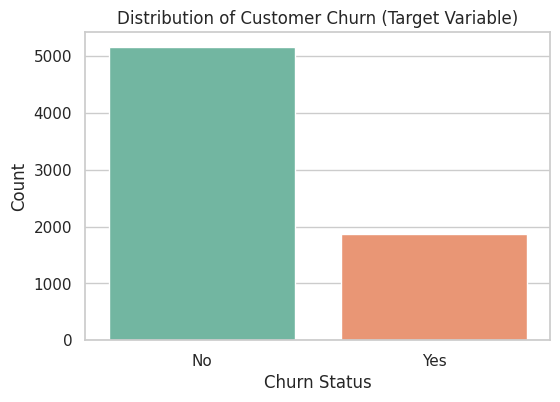

In [ ]:


plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Distribution of Customer Churn (Target Variable)')
plt.xlabel('Churn Status')
plt.ylabel('Count')
plt.show()




Plots a Seaborn countplot to visualize the class balance of the target variable

# **Phase 4: Exploratory Data Analysis (EDA) - Feature Distributions & Outliers**

### **Checking Outliers in Numerical Features**

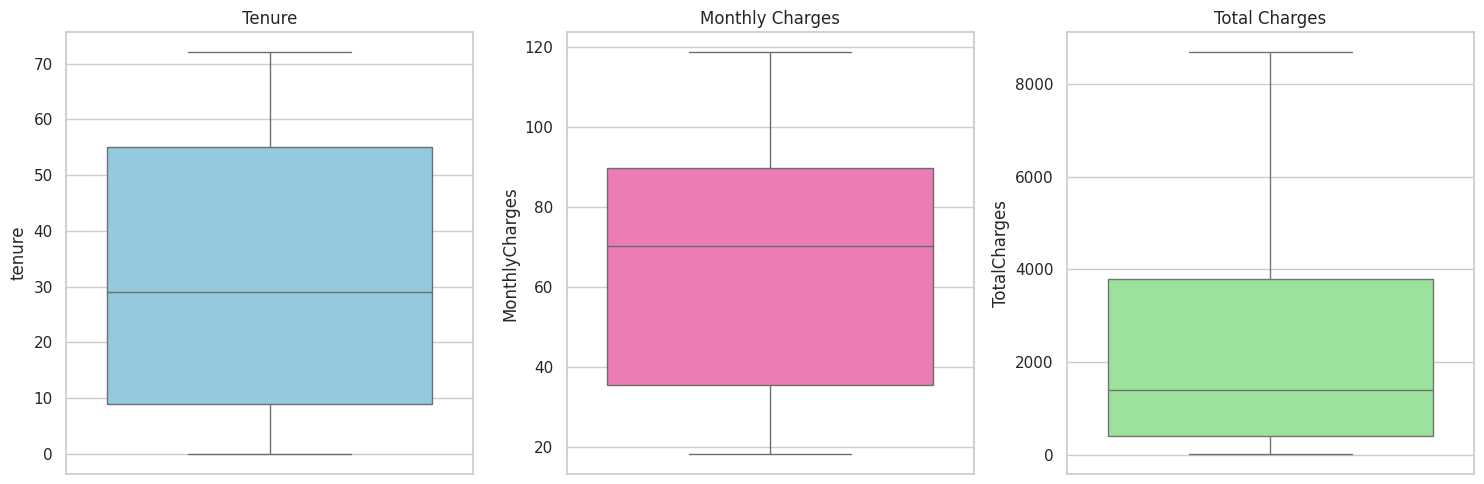

In [ ]:
# ==============================================
# Boxplots to Detect Outliers in Numerical Features
# ==============================================

plt.subplots(1, 3, figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['tenure'], color='skyblue')
plt.title('Tenure')

plt.subplot(1, 3, 2)
sns.boxplot(y=df['MonthlyCharges'], color='hotpink')
plt.title('Monthly Charges')

plt.subplot(1, 3, 3)
sns.boxplot(y=df['TotalCharges'], color='lightgreen')
plt.title('Total Charges')

plt.tight_layout()
plt.show()

### **Visualizing Numerical Features Distribution via Violin Plots**

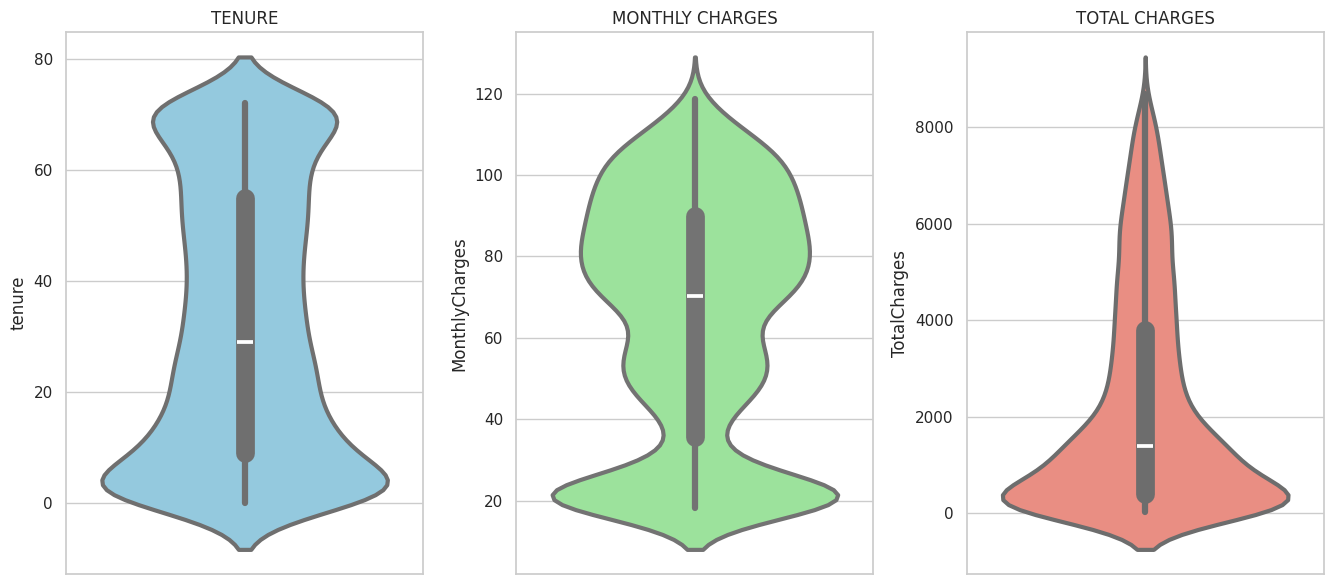

In [ ]:
# Violin Plots to Inspect Distribution & Spread of Numerical Features

plt.figure(figsize=(18, 6))

plt.subplot(1, 4, 1)
plt.title('TENURE')
sns.violinplot(y='tenure', data=df, color='skyblue', linewidth=3)

plt.subplot(1, 4, 2)
plt.title('MONTHLY CHARGES')
sns.violinplot(y='MonthlyCharges', data=df, color='lightgreen', linewidth=3)

plt.subplot(1, 4, 3)
plt.title('TOTAL CHARGES')
sns.violinplot(y='TotalCharges', data=df, color='salmon', linewidth=3)

plt.tight_layout()
plt.show()

### **Plot the first histogram with KDE, differentiated by Churn status (Overall)**

Text(0, 0.5, 'Frequency')

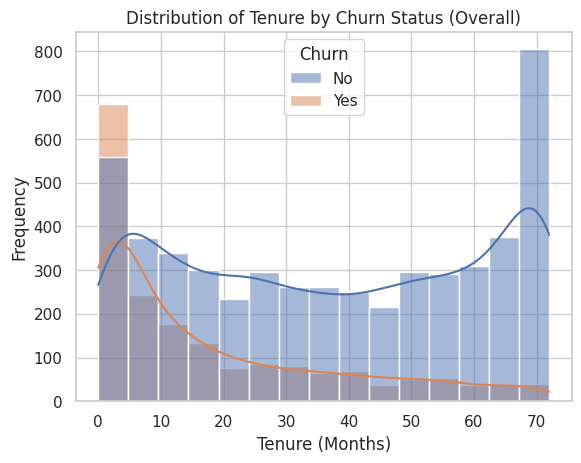

In [ ]:
# Plot the first histogram with KDE, differentiated by Churn status (Overall)
sns.histplot(data=df, x='tenure', kde=True, hue='Churn')
plt.title('Distribution of Tenure by Churn Status (Overall)')
plt.xlabel('Tenure (Months)')
plt.ylabel('Frequency')

### **KDE for Monthly Charges and Tenure, differentiated by Churn status**

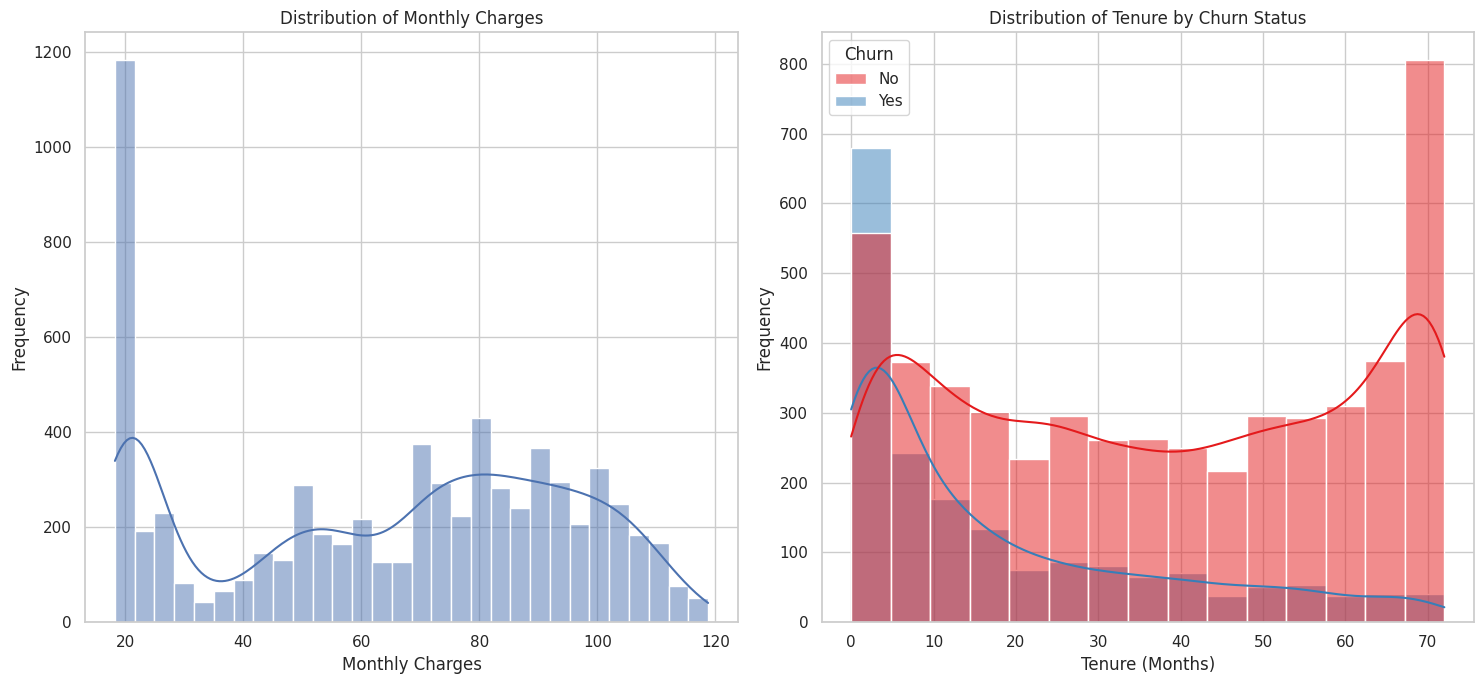

In [ ]:
# Create a subplot with two histograms side by side
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

# Plot the first histogram with KDE for Monthly Charges
plt.subplot(121)
sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True, color='b')
plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Frequency')

# Plot the second histogram with KDE for Tenure, differentiated by Churn status
plt.subplot(122)
sns.histplot(data=df, x='tenure', kde=True, hue='Churn', palette='Set1')
plt.title('Distribution of Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Frequency')

# Display the subplots
plt.tight_layout()
plt.show()

# **Phase 5: Preprocessing & Feature Engineering**

### **Feature Selection & Encoding**

In [ ]:
print("Columns in dataframe:", df.columns.tolist())
print("Unique values in target column (if any):")

# Detect the target column without hard-coding capitalization
target_col = next(
    (col for col in df.columns if col.strip().lower() in ["churn", "target", "class", "label"]),
    None
)
print(f"Detected target column: {target_col}")

if target_col is None:
    raise ValueError("Target column could not be found. Check the dataset columns.")

print(df[target_col].value_counts(dropna=False))

# Customer ID is an identifier, so exclude it from model features
customer_id_columns = [col for col in df.columns if col.strip().lower() == "customerid"]
df = df.drop(columns=customer_id_columns, errors="ignore")

# Normalize target labels and map churn to 1, non-churn to 0
df[target_col] = df[target_col].astype(str).str.strip().str.lower()
target_mapping = {"yes": 1, "no": 0, "true": 1, "false": 0, "1": 1, "0": 0}
df[target_col] = df[target_col].map(target_mapping)
df = df.dropna(subset=[target_col]).copy()
df[target_col] = df[target_col].astype(int)
print(f"Rows remaining after cleaning target: {len(df)}")

# Separate target and features
X = df.drop(columns=[target_col])
y = df[target_col]

# Encode categorical features using a reusable function
X = encode_features(X)
print("Shape of X after One-Hot Encoding:", X.shape)

X.head()


Columns in dataframe: ['CustomerID', 'Gender', 'IsSeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Unique values in target column (if any):
Detected target column: Churn
Churn
No     5166
Yes    1869
Name: count, dtype: int64
Rows remaining after cleaning target: 7035
Shape of X after One-Hot Encoding: (7035, 30)


,tenure,MonthlyCharges,TotalCharges,Gender_Male,IsSeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,29.85,29.85,0,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,34,56.95,1889.50,1,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,2,53.85,108.15,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,45,42.30,1840.75,1,0,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,2,70.70,151.65,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [ ]:
# Separate features and target
X = df.drop(columns=['Churn'])
y = df['Churn']

# One-hot encode categorical features
X_encoded = encode_features(X)

# Train-test split (80/20) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Cap outliers on continuous features using training set IQR
continuous_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
X_train, X_test, bounds = DataProcessor.cap_iqr_outliers(X_train, X_test, continuous_cols)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (5628, 30)
X_test shape: (1407, 30)


Cleans the target column, maps it to binary values (0 and 1), drops the customerID column, drops rows with missing target values, and applies One-Hot Encoding to categorical features.

### **Train-Test Split & Scaling**

In [ ]:
# Split into training and testing sets (stratified to preserve churn proportions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Handle potential outliers in continuous numeric columns.
# Bounds are learned from X_train only and then applied to X_test.
continuous_columns = [
    column for column in ["tenure", "MonthlyCharges", "TotalCharges"]
    if column in X_train.columns
]
X_train, X_test, outlier_bounds = DataProcessor.cap_iqr_outliers(
    X_train, X_test, continuous_columns
)
print("IQR bounds learned from training data:")
for column, (lower, upper) in outlier_bounds.items():
    print(f"{column}: lower={lower:.3f}, upper={upper:.3f}")

# Scale using training data only
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)


Training samples: 5628
Testing samples: 1407
IQR bounds learned from training data:
tenure: lower=-61.500, upper=126.500
MonthlyCharges: lower=-46.300, upper=171.700
TotalCharges: lower=-4682.488, upper=8901.513


Splits the data into 80% training and 20% testing sets using stratification on the target variable and normalizes the features using

# **Phase 6: Supervised Machine Learning Modeling**

### **Define Multiple Classifiers**

In [ ]:
# Define multiple machine learning classifiers
# supervised_models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=100, random_state=42),
    "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42)
}

Initializes a dictionary containing six different machine learning models:

*   Logistic Regression
*   Decision Tree
*   Random Forest
*   K-Nearest
*   Naive Bayes
*   Support Vector Machine (SVM)

### **Train Supervised Machine Learning model and Collect Results**

In [ ]:
# Train and compare supervised models using the ModelTrainer class
trainer = ModelTrainer(models)
results_df = trainer.train_and_evaluate(
    X_train_scaled, X_test_scaled, y_train, y_test
)

display(results_df)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.807392,0.658462,0.572193,0.612303,0.841612
1,SVM,0.798863,0.663082,0.494652,0.566616,0.800336
2,Random Forest Classifier,0.796020,0.649485,0.505348,0.568421,0.823669
3,Decision Tree Classifier,0.788202,0.631034,0.489305,0.551205,0.820773
4,K-Nearest Neighbors (KNN),0.761194,0.553073,0.529412,0.540984,0.777191
5,Naive Bayes,0.656716,0.428005,0.866310,0.572944,0.813486


### **Feature Importance (Random Forest)**

In [ ]:
# Feature Importance Bar Chart using Random Forest
# Fit only on the training data to avoid using the test set for feature selection.
rf_importance_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_importance_model.fit(X_train_scaled, y_train)

importances = rf_importance_model.feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=feature_importance_df, palette="viridis")
plt.title("Top 15 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


ValueError: All arrays must be of the same length

Iterates through the models, trains them on the scaled training data, computes test accuracy, and compiles the results into a sorted DataFrame.

# **Phase 7: Supervised Model Evaluation & Visualization**

### **Classification report for each supervised model**

In [ ]:
# Print detailed classification report for each supervised model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, predictions)

    print(f"\n================ {name} ================")
    print(f"Accuracy: {acc * 100:.2f}%")
    print(f"Classification Report:\n")
    print(classification_report(y_test, predictions))

Generates and prints detailed classification reports (including precision, recall, and F1-score) for each supervised classifier.

### **Compare Model Performance (Bar Chart)**

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette="viridis")
plt.title("Model Accuracy Comparison")
plt.xlim(0, 1)
plt.show()



Plots a Seaborn bar chart to visually compare the accuracy scores across all evaluated models.

### **Confusion Matrix Heatmaps for each model**

In [ ]:
# Generate Confusion Matrix Heatmaps for each model (Separate charts)
for name, model in models.items():
    predictions = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix: {name}')
    plt.show()

Generates and displays individual Seaborn confusion matrix heatmaps for each classifier to evaluate true/false positives and negatives.

### **ROC Curve Comparison for All Models**

In [ ]:
# Combined ROC Curve Comparison for Models that provide probabilities
plt.figure(figsize=(8, 6))

for name, model in models.items():
    if not hasattr(model, "predict_proba"):
        print(f"Skipping ROC curve for {name}: predict_proba is unavailable.")
        continue
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - All Models")
plt.legend(loc="lower right")
plt.show()


Logistic Regression leads with the strongest discriminative performance at an AUC of 0.84. It is closely followed by the tree-based classifiers and Naive Bayes (AUCs ranging from 0.81 to 0.82), while KNN trails slightly behind at 0.78, indicating that linear and probabilistic models capture the churn boundaries more effectively for this dataset.

### **Best Model Confusion Matrix & Classification Report**

In [ ]:
# Pick the best-performing model automatically
best_model_name = results_df.iloc[0, 0]
best_model = models[best_model_name]

y_pred = best_model.predict(X_test_scaled)

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Stay (0)', 'Churn (1)'], yticklabels=['Stay (0)', 'Churn (1)'])
plt.title(f"Confusion Matrix - {best_model_name}")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(f"Classification Report for {best_model_name}:\n")
print(classification_report(y_test, y_pred))

The Logistic Regression model achieves a strong overall accuracy of 81%. While it excels at correctly predicting customers who will stay (F1-score of 0.87), it faces typical challenges with class imbalance when identifying actual churners (recall of 0.57 and precision of 0.66). Overall, it serves as a reliable baseline for customer retention analysis.

# **Phase 8: Unsupervised Learning & Customer Segmentation**

### **Unsupervised Learning - K-Means Clustering (Customer Segmentation)**

In [ ]:
# ==============================================
# Unsupervised Learning: K-Means Clustering
# ==============================================

# Combine scaled training and testing features for overall customer segmentation
full_scaled = np.vstack((X_train_scaled, X_test_scaled))

# Apply K-Means Clustering (e.g., 3 customer segments)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(full_scaled)
print(f"-> K-Means Clustering completed. Generated 3 unique customer behavioral segments.")

# Reduce dimensions to 2D using PCA for visualization
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(full_scaled)

# Visualize K-Means Clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x=reduced_features[:, 0], y=reduced_features[:, 1], hue=clusters, palette='viridis', alpha=0.8)
plt.title('K-Means Customer Segments (PCA-reduced)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

### **Unsupervised Learning - Isolation Forest (Anomaly Detection)**

In [ ]:
# ==============================================
# Unsupervised Learning: Isolation Forest (Anomalies)
# ==============================================

# Apply Isolation Forest to detect unusual or anomalous accounts
iso = IsolationForest(contamination=0.03, random_state=42)
anomalies = iso.fit_predict(full_scaled) # -1 for anomalies/outliers, 1 for normal
num_anomalies = np.sum(anomalies == -1)
print(f"-> Isolation Forest completed. Detected {num_anomalies} unusual/anomalous accounts.")

# Create a dataframe for plotting anomalies
plot_df = pd.DataFrame(reduced_features, columns=['PC1', 'PC2'])
plot_df['Anomaly'] = anomalies

# Visualize Isolation Forest Anomalies
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x='PC1',
    y='PC2',
    hue='Anomaly',
    palette=['red', 'blue'], # Red for anomalies, blue for normal
    alpha=0.7
)
plt.title('Isolation Forest Anomaly Detection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

# Conclusion & Business Insights

## 1. Model Performance & Predictive Power
* **Logistic Regression**: Emerged as the top-performing classifier, achieving an overall accuracy of **81%** and a strong ROC-AUC score of **0.84**, demonstrating robust discriminative ability.
* **Alternative Classifiers**: Tree-based models (Decision Tree and Random Forest) and Naive Bayes followed closely with AUC scores ranging from **0.81 to 0.82**, while KNN trailed slightly.

## 2. Key Drivers of Churn
* **Feature Importance**: Analysis via Random Forest and distribution plots highlighted that customer **tenure**, **monthly charges**, and contract types are critical predictors.
* **Behavioral Trends**: Newer customers with high monthly bills and month-to-month contracts exhibit significantly higher churn rates compared to long-term subscribers.

## 3. Customer Segmentation (Unsupervised Learning)
* **Behavioral Profiling**: Utilizing **PCA and K-Means clustering** successfully grouped customers into distinct behavioral clusters, enabling the business to pinpoint high-risk segments proactively.

## 4. Actionable Business Recommendations
* **Targeted Retention**: Focus proactive retention offers and contract-upgrade incentives on early-tenure customers and month-to-month subscribers.
* **Billing Optimization**: Review pricing structures for high-monthly-charge segments to mitigate price-sensitivity drop-offs.